In [1]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import sys, os
sys.path.append(os.path.abspath("../data_creation/plots_and_analysis"))
import config
# adjust paths in /data_creation/plots_and_analysis/config.py


In [2]:
config.path_to_evaluation

'/home/dev/projects/data/evaluation/'

In [3]:
# get accuracy metrics
all_metrics_df = pd.read_parquet(f"{config.path_to_evaluation}/results.parquet")
all_metrics_df["div_step"] = all_metrics_df["div_step"].astype(str)
all_metrics_df.rename(columns={"div_step": "div", "pot target size": "p"}, inplace=True)
all_metrics_df


/home/dev/projects/ecml_publication/.venv/lib/python3.10/site-packages/fastparquet/dataframe.py:5: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import (


,RMSSE,MASE,sMAPE,p,similarity,div,run
0,0.478,0.714,0.304,5000,7.05,10,case1_run1
1,0.413,0.595,0.307,12000,7.22,10,case1_run1
2,0.386,0.568,0.323,25000,8.06,10,case1_run1
3,0.404,0.605,0.327,50000,8.26,10,case1_run1
4,0.602,0.807,0.391,100000,9.36,10,case1_run1
...,...,...,...,...,...,...,...
100,0.331,0.574,0.333,25000,8.06,0,case1_run5
101,0.337,0.578,0.330,50000,8.24,0,case1_run5
102,0.599,0.814,0.394,100000,9.31,0,case1_run5
103,0.504,0.743,0.374,all,9.71,0,case1_run5


In [4]:
# append target features
mean_target_features = pd.read_parquet(f"{config.path_to_evaluation}/target_features_num.parquet")
all_metrics_df = all_metrics_df.merge(mean_target_features,on=["p", "div", "run"], how="outer")
all_metrics_df


,RMSSE,MASE,sMAPE,p,similarity,div,run,abs_energy,intermittency,mean,median,kurtosis,skewness,standard_deviation,agg_autocorrelation_max,erraticness,agg_linear_trend_slope
0,0.478,0.714,0.304,5000,7.05,10,case1_run1,3.689753e+14,1.035938,35032.743277,29439.600093,30.812523,4.309848,23687.416511,0.558057,4.697648,63.705527
1,0.413,0.595,0.307,12000,7.22,10,case1_run1,1.108609e+13,1.177604,13026.045133,10525.194740,35.433874,4.720662,13159.127455,0.529577,5.547235,-25.437770
2,0.386,0.568,0.323,25000,8.06,10,case1_run1,2.144351e+11,1.208289,9025.517284,6811.242522,37.928368,4.896411,9545.965726,0.515717,7.228339,4.784278
3,0.404,0.605,0.327,50000,8.26,10,case1_run1,7.910557e+10,1.165185,5678.548015,4088.920312,37.852621,4.905764,7047.853817,0.496000,6.942911,6.920892
4,0.602,0.807,0.391,100000,9.36,10,case1_run1,9.839514e+12,1.370891,15687.311702,14271.434325,27.019483,3.838687,7682.077810,0.479000,3.631237,-10.298523
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,0.331,0.574,0.333,25000,8.06,0,case1_run5,9.307376e+11,1.203604,10095.383562,7646.423652,38.151379,4.923845,9901.003077,0.513596,7.257290,8.913301
101,0.337,0.578,0.330,50000,8.24,0,case1_run5,1.851746e+12,1.135656,7694.416570,6074.169946,38.188446,4.927221,7524.462372,0.490967,7.350120,-9.871640
102,0.599,0.814,0.394,100000,9.31,0,case1_run5,8.461348e+13,1.418537,21975.314520,20863.996307,26.036912,3.773824,7937.833814,0.487701,3.345940,-15.780214
103,0.504,0.743,0.374,all,9.71,0,case1_run5,2.501179e+14,1.331803,33504.905493,31466.569101,31.161367,4.243324,12615.855934,0.485308,4.838056,-105.733174


In [6]:
all_metrics_df.columns

Index(['RMSSE', 'MASE', 'sMAPE', 'p', 'similarity', 'div', 'run', 'abs_energy',
       'intermittency', 'mean', 'median', 'kurtosis', 'skewness',
       'standard_deviation', 'agg_autocorrelation_max', 'erraticness',
       'agg_linear_trend_slope'],
      dtype='object')

In [7]:
# load source features
mean_source_features = pd.read_parquet(f"{config.path_to_evaluation}/source_features_num.parquet")
mean_source_features

,div,run,number_of_non_zero,erraticness,intermittency,abs_energy,absolute_sum_of_changes,agg_autocorrelation_max,agg_linear_trend_slope,index_mass_quantile_02,...,quantile_0_4,quantile_0_5,quantile_0_6,quantile_0_7,quantile_0_8,quantile_0_9,ratio_value_unique_value,skewness,standard_deviation,variation_coefficient
0,10,case1_run1,120.850046,4.461508,1.344496,1.085585e+14,264619.490716,0.484488,-7.764684,0.322506,...,10996.920765,11653.785174,12579.123212,14011.268201,16016.110907,19210.927904,0.657858,4.121756,8296.491242,1.648400
1,10,case1_run2,120.757109,4.422811,1.343005,9.464328e+13,256922.385933,0.484409,-6.598869,0.322052,...,9602.811907,10230.385389,11100.364909,12502.054112,14435.792757,17552.555690,0.658035,4.116992,8085.265459,1.641543
2,10,case1_run3,120.707046,4.443479,1.345218,1.053131e+14,261275.956011,0.484907,-7.568033,0.322619,...,10725.221912,11390.653282,12335.060394,13779.814436,15817.687531,19046.451841,0.658806,4.120933,8268.345239,1.647032
3,10,case1_run4,120.558002,4.464509,1.343914,1.042806e+14,265188.578036,0.484957,-4.178616,0.322677,...,10651.273871,11275.830991,12161.114138,13563.805007,15550.347994,18786.045676,0.658154,4.121094,8265.682284,1.648954
4,10,case1_run5,120.627995,4.443689,1.340569,4.436432e+13,244632.957995,0.484516,-4.214499,0.322273,...,9635.650163,10227.382349,10945.562821,11945.745570,13367.322307,16078.028642,0.658598,4.121640,7463.632820,1.644796
5,5,case1_run1,120.636156,4.422136,1.341896,9.726721e+13,259620.182539,0.485258,-2.979981,0.322285,...,10050.582647,10646.175150,11494.607113,12875.565882,14769.597860,17888.388009,0.658278,4.116344,8019.513813,1.642505
6,5,case1_run2,120.797636,4.415750,1.346073,9.699733e+13,253859.146002,0.485133,-3.348870,0.322591,...,9785.729665,10372.199295,11191.883870,12525.750204,14372.019682,17425.473291,0.657429,4.115769,7909.951816,1.645566
7,5,case1_run3,120.486416,4.437755,1.343923,9.690224e+13,258801.686927,0.484892,-2.751997,0.322906,...,9944.650843,10530.414814,11371.650337,12738.421615,14607.117487,17666.765801,0.657443,4.114878,8040.333650,1.645054
8,5,case1_run4,120.714510,4.397455,1.343211,1.019307e+14,257775.686194,0.485127,-4.897063,0.322337,...,10035.961005,10616.950308,11461.115460,12804.248621,14706.917459,17811.723030,0.658525,4.116332,8043.605112,1.641623
9,5,case1_run5,120.603533,4.448987,1.343406,9.779106e+13,261289.151756,0.484601,-3.566613,0.322387,...,10428.587039,11040.300694,11906.582374,13322.135132,15254.319905,18446.000487,0.658578,4.123876,8040.365234,1.648050


In [8]:
# merge with source features
# Merge the dataframes on 'div' and 'run' keys
merged_df = all_metrics_df.merge(
    mean_source_features, 
    on=['div', 'run'], 
    how='left', 
    suffixes=('', '_source')
)

# Fill missing values in rows where p='source'
mask = merged_df['p'] == 'source'

feature_columns = set(mean_source_features.columns) - set(["div", "run"])

#feature_columns = [col for col in all_metrics_df.columns if col not in ['RMSSE', 'MASE', 'sMAPE', 'p', 'similarity', 'div', 'run']]

for col in feature_columns:
    if f'{col}_source' in merged_df.columns:
        merged_df.loc[mask, col] = merged_df.loc[mask, col].fillna(merged_df.loc[mask, f'{col}_source'])

source_cols = [col for col in merged_df.columns if col.endswith('_source')]
merged_df = merged_df.drop(columns=source_cols)

all_metrics_df = merged_df
all_metrics_df.rename(columns={"agg_autocorrelation_max":"autocorr", "agg_linear_trend_slope":"trend", "standard_deviation":"sd"}, inplace=True)
all_metrics_df.to_parquet(f"{config.path_to_evaluation}/results_metrics_features.parquet")
all_metrics_df

,RMSSE,MASE,sMAPE,p,similarity,div,run,abs_energy,intermittency,mean,...,quantile_0_2,quantile_0_3,quantile_0_4,quantile_0_5,quantile_0_6,quantile_0_7,quantile_0_8,quantile_0_9,ratio_value_unique_value,variation_coefficient
0,0.478,0.714,0.304,5000,7.05,10,case1_run1,3.689753e+14,1.035938,35032.743277,...,9833.973344,10469.352053,10996.920765,11653.785174,12579.123212,14011.268201,16016.110907,19210.927904,0.657858,1.648400
1,0.413,0.595,0.307,12000,7.22,10,case1_run1,1.108609e+13,1.177604,13026.045133,...,9833.973344,10469.352053,10996.920765,11653.785174,12579.123212,14011.268201,16016.110907,19210.927904,0.657858,1.648400
2,0.386,0.568,0.323,25000,8.06,10,case1_run1,2.144351e+11,1.208289,9025.517284,...,9833.973344,10469.352053,10996.920765,11653.785174,12579.123212,14011.268201,16016.110907,19210.927904,0.657858,1.648400
3,0.404,0.605,0.327,50000,8.26,10,case1_run1,7.910557e+10,1.165185,5678.548015,...,9833.973344,10469.352053,10996.920765,11653.785174,12579.123212,14011.268201,16016.110907,19210.927904,0.657858,1.648400
4,0.602,0.807,0.391,100000,9.36,10,case1_run1,9.839514e+12,1.370891,15687.311702,...,9833.973344,10469.352053,10996.920765,11653.785174,12579.123212,14011.268201,16016.110907,19210.927904,0.657858,1.648400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,0.331,0.574,0.333,25000,8.06,0,case1_run5,9.307376e+11,1.203604,10095.383562,...,5947.696611,6371.742929,6783.848499,7274.612448,7863.556858,8663.484358,9893.077094,12399.102173,0.658872,1.642523
101,0.337,0.578,0.330,50000,8.24,0,case1_run5,1.851746e+12,1.135656,7694.416570,...,5947.696611,6371.742929,6783.848499,7274.612448,7863.556858,8663.484358,9893.077094,12399.102173,0.658872,1.642523
102,0.599,0.814,0.394,100000,9.31,0,case1_run5,8.461348e+13,1.418537,21975.314520,...,5947.696611,6371.742929,6783.848499,7274.612448,7863.556858,8663.484358,9893.077094,12399.102173,0.658872,1.642523
103,0.504,0.743,0.374,all,9.71,0,case1_run5,2.501179e+14,1.331803,33504.905493,...,5947.696611,6371.742929,6783.848499,7274.612448,7863.556858,8663.484358,9893.077094,12399.102173,0.658872,1.642523


To avoid collinearity in the linear regression, calculate the Pearson correlation matrix.

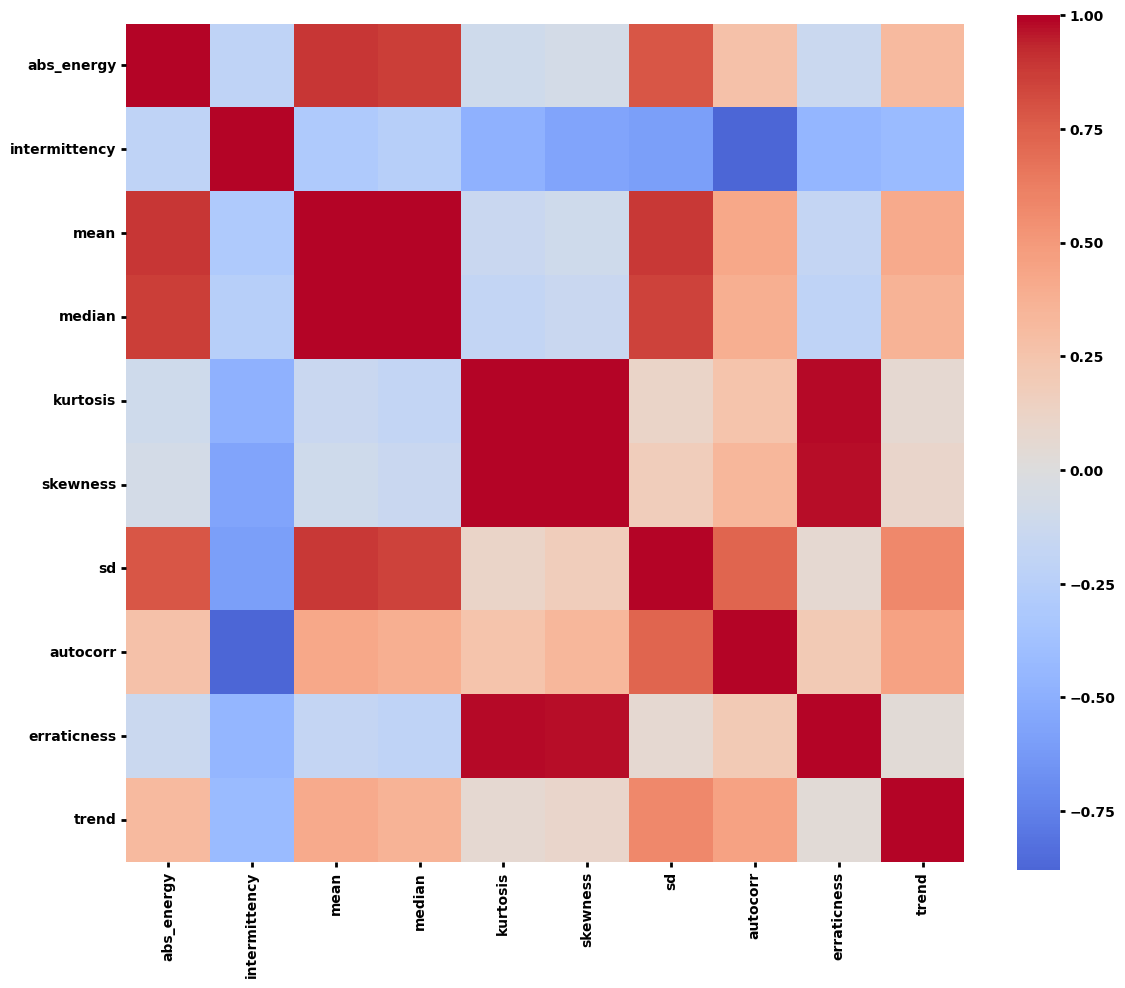

In [9]:
features = ['abs_energy', 'intermittency', 'mean', 'median', 'kurtosis', 
                     'skewness', 'sd', 'autocorr', 
                     'erraticness', 'trend']


div = "aggregated" #choose between: "0", "5", "10", "aggregated"

if div == "aggregated":
    complete_data = all_metrics_df[features].dropna() 
else:
    complete_data = all_metrics_df.loc[all_metrics_df["div"] == div][features].dropna()
    
correlation_matrix = complete_data.corr()

plt.rcParams.update({
    'font.size': 12,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'xtick.major.width': 2,
    'ytick.major.width': 2,
    'axes.linewidth': 2
})

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0, 
            square=True, fmt='.2f', 
            annot_kws={'weight': 'bold', 'size': 10}) 
plt.tight_layout()  
plt.savefig(f"{config.path_to_evaluation}/feature_correlations_div{div}.pdf",  bbox_inches='tight')
plt.show()